Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
from pathlib import Path
from urllib.request import urlretrieve

# Project folders
project_dir = Path.cwd().resolve().parent
data_dir = project_dir / "data"
data_dir.mkdir(parents=True, exist_ok=True)

# GEO supplementary file
url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE190nnn/GSE190639/suppl/"
    "GSE190639_Broekhuizen_Raw_data.xlsx"
)

file_path = data_dir / "GSE190639_Broekhuizen_Raw_data.xlsx"

# Download the file
if not file_path.exists():
    urlretrieve(url, file_path)

print("Downloaded successfully!")
print("File location:", file_path)

Downloaded successfully!
File location: /Users/tavimangoma/Documents/Preeclampsia_NanoString_Project/Preeclampsia_NanoString/data/GSE190639_Broekhuizen_Raw_data.xlsx


In [3]:
import pandas as pd

# Open Excel workbook
excel_file = pd.ExcelFile(file_path)

# Show available sheets
print("Available sheets:")
print(excel_file.sheet_names)

Available sheets:
['Raw data of 35 samples', 'Sheet1']


In [4]:
# Load the first sheet
df = pd.read_excel(file_path, sheet_name=0)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (785, 37)


,Raw count data per sample ID,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36
0,Probe Name,Class Name,155,157,158,136,137,159,160,161,...,135,152,155,157,180,210,221,251,288,289
1,POS_A,Positive,986,931,134,16053,20352,24813,24421,21596,...,19258,16453,16986,16682,18221,16398,16872,15631,16421,18334
2,POS_B,Positive,355,327,27,6150,7382,8444,8147,7710,...,6770,6094,6076,5891,6828,6164,5982,5690,6017,6545
3,POS_C,Positive,81,81,9,1632,2024,2348,2259,2026,...,1579,1577,1540,1539,1761,1604,1485,1486,1493,1708
4,POS_D,Positive,29,30,3,393,516,605,574,489,...,429,400,370,394,417,394,365,386,411,392


In [5]:
import pandas as pd

# Reload the Excel file using the second row as the header
df = pd.read_excel(
    file_path,
    sheet_name=0,
    header=1
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (784, 37)


,Probe Name,Class Name,155,157,158,136,137,159,160,161,...,135,152,155.1,157.1,180,210,221,251,288,289
0,POS_A,Positive,986,931,134,16053,20352,24813,24421,21596,...,19258,16453,16986,16682,18221,16398,16872,15631,16421,18334
1,POS_B,Positive,355,327,27,6150,7382,8444,8147,7710,...,6770,6094,6076,5891,6828,6164,5982,5690,6017,6545
2,POS_C,Positive,81,81,9,1632,2024,2348,2259,2026,...,1579,1577,1540,1539,1761,1604,1485,1486,1493,1708
3,POS_D,Positive,29,30,3,393,516,605,574,489,...,429,400,370,394,417,394,365,386,411,392
4,POS_E,Positive,2,4,1,54,76,87,84,82,...,58,51,54,53,49,64,55,39,50,50


In [6]:
# Display all column names
print("Column names:")
print(df.columns.tolist())

# Examine probe classifications
print("\nProbe classifications:")
print(df["Class Name"].value_counts(dropna=False))

# Check the dataset dimensions
print("\nDataset shape:", df.shape)


Column names:
['Probe Name', 'Class Name', 155, 157, 158, 136, 137, 159, 160, 161, 163, 165, 168, 170, 172, 174, 175, 144, 150, 154, 176, 197, 219, 220, 232, 237, 130, 135, 152, '155.1', '157.1', 180, 210, 221, 251, 288, 289]

Probe classifications:
Class Name
Endogenous      730
Housekeeping     40
Negative          8
Positive          6
Name: count, dtype: int64

Dataset shape: (784, 37)


In [7]:
# Sample columns begin after Probe Name and Class Name
sample_columns = df.columns[2:]

print("Number of sample columns:", len(sample_columns))

print("\nSample column names:")
print(sample_columns.tolist())

print("\nDuplicate column identifiers:")
print(sample_columns[
    sample_columns.duplicated()
].tolist())

Number of sample columns: 35

Sample column names:
[155, 157, 158, 136, 137, 159, 160, 161, 163, 165, 168, 170, 172, 174, 175, 144, 150, 154, 176, 197, 219, 220, 232, 237, 130, 135, 152, '155.1', '157.1', 180, 210, 221, 251, 288, 289]

Duplicate column identifiers:
[]


In [8]:
# Sample IDs verified against GEO
early_onset = [
    136, 137, 161, 170, 172, 175, 176,
    197, 219, 220, 232, 237, 251
]

late_onset = [
    130, 135, 152, 180, 210, 221
]

healthy = [
    144, 150, 154, "155.1", "157.1",
    159, 160, 163, 165, 168, 174, 288, 289
]

# Create mapping
sample_groups = {}

for sample in early_onset:
    sample_groups[sample] = "Early-onset PE"

for sample in late_onset:
    sample_groups[sample] = "Late-onset PE"

for sample in healthy:
    sample_groups[sample] = "Healthy"

# Confirm all samples exist
assert all(s in df.columns for s in sample_groups)

print("Early-onset:", len(early_onset))
print("Late-onset:", len(late_onset))
print("Healthy:", len(healthy))
print("Total:", len(sample_groups))

Early-onset: 13
Late-onset: 6
Healthy: 13
Total: 32


In [9]:
# Keep endogenous immune-related genes only
genes = df[df["Class Name"] == "Endogenous"].copy()

# Retain the 32 GEO-registered samples
expression = genes[
    ["Probe Name"] + list(sample_groups.keys())
].copy()

# Set gene names as row labels
expression = expression.set_index("Probe Name")

# Convert expression counts to numeric values
expression = expression.apply(pd.to_numeric, errors="coerce")

# Standardize column names
expression.columns = [str(c).replace(".1", "") for c in expression.columns]

print("Expression matrix:", expression.shape)
display(expression.iloc[:5, :5])

Expression matrix: (730, 32)


,136,137,161,170,172
Probe Name,,,,,
A2M,23935,16698,16101,14400,15371
ABCB1,5268,4956,5849,3884,4335
ABL1,1277,803,1028,865,833
ADA,144,224,131,64,74
ADORA2A,53,39,56,44,37


In [10]:
metadata = pd.DataFrame({
    "Sample_ID": [
        str(s).replace(".1", "")
        for s in sample_groups
    ],
    "Group": list(sample_groups.values())
})

print(metadata["Group"].value_counts())
display(metadata.head(10))

Group
Early-onset PE    13
Healthy           13
Late-onset PE      6
Name: count, dtype: int64


,Sample_ID,Group
0,136,Early-onset PE
1,137,Early-onset PE
2,161,Early-onset PE
3,170,Early-onset PE
4,172,Early-onset PE
5,175,Early-onset PE
6,176,Early-onset PE
7,197,Early-onset PE
8,219,Early-onset PE
9,220,Early-onset PE


In [11]:
# Save cleaned expression matrix and metadata
expression.to_csv(data_dir / "expression_raw.csv", index=True)

metadata.to_csv(
    data_dir / "sample_metadata.csv",
    index=False
)

print("Files saved successfully!")

Files saved successfully!


Quality Control

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Check for missing values
print("Missing values:", expression.isna().sum().sum())

# Check for negative counts
print("Negative counts:", (expression < 0).sum().sum())

# Check number of genes and samples
print("Number of genes:", expression.shape[0])
print("Number of samples:", expression.shape[1])

# Check for genes with zero counts in all samples
print(
    "Genes with all-zero counts:",
    (expression.sum(axis=1) == 0).sum()
)

Missing values: 0
Negative counts: 0
Number of genes: 730
Number of samples: 32
Genes with all-zero counts: 0


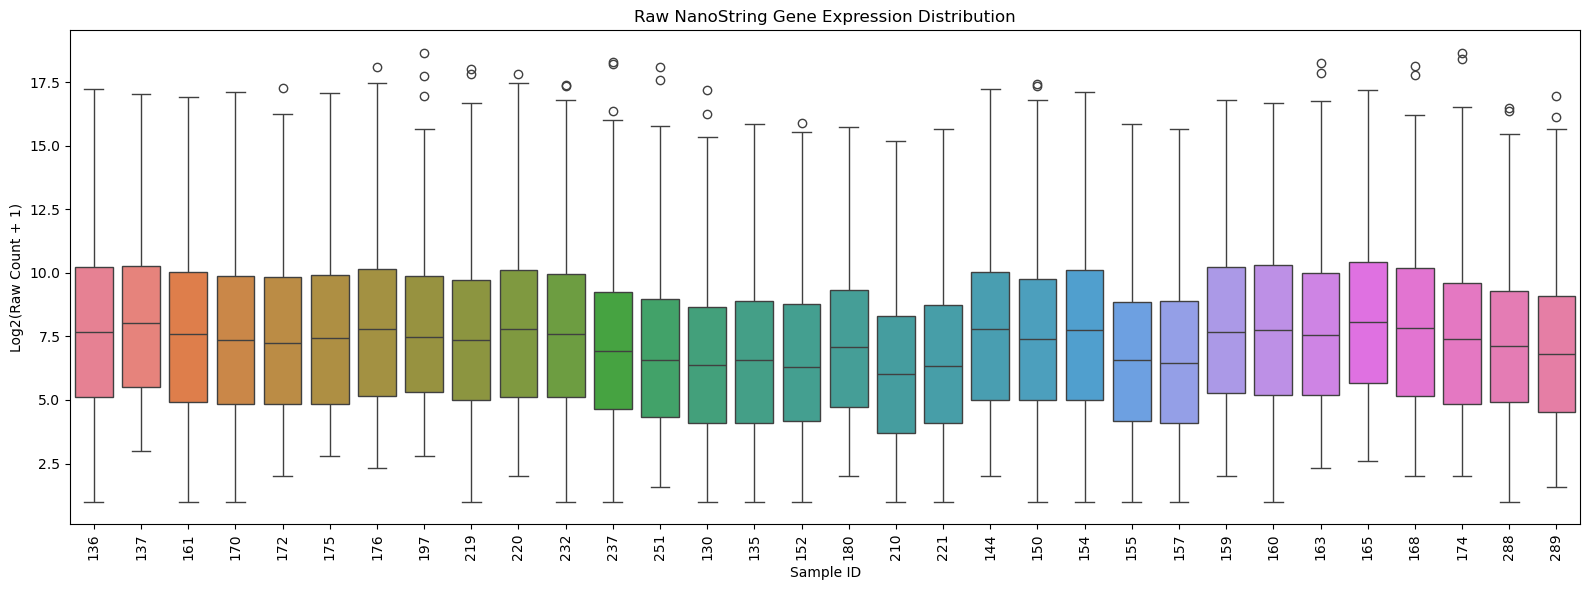

In [13]:
# Log transformation for visualization only
log_expression = np.log2(expression + 1)

plt.figure(figsize=(16, 6))

sns.boxplot(data=log_expression)

plt.xticks(rotation=90)
plt.xlabel("Sample ID")
plt.ylabel("Log2(Raw Count + 1)")
plt.title("Raw NanoString Gene Expression Distribution")

plt.tight_layout()
plt.show()

In [14]:
# Keep only the 32 selected samples
selected_samples = list(sample_groups.keys())

# Extract control probes
positive_controls = df[
    df["Class Name"] == "Positive"
].set_index("Probe Name")[selected_samples]

negative_controls = df[
    df["Class Name"] == "Negative"
].set_index("Probe Name")[selected_samples]

# Convert to numbers
positive_controls = positive_controls.apply(
    pd.to_numeric, errors="coerce"
)

negative_controls = negative_controls.apply(
    pd.to_numeric, errors="coerce"
)

# Use consistent sample labels
sample_ids = expression.columns.tolist()

positive_controls.columns = sample_ids
negative_controls.columns = sample_ids

# Calculate summary statistics
control_summary = pd.DataFrame({
    "Positive_Mean": positive_controls.mean(axis=0),
    "Negative_Mean": negative_controls.mean(axis=0),
    "Negative_SD": negative_controls.std(axis=0)
})

display(control_summary.head())

,Positive_Mean,Negative_Mean,Negative_SD
136,4051.833333,13.375,5.705574
137,5063.833333,16.625,6.610327
161,5321.666667,17.500,4.342481
170,5665.666667,18.000,3.464102
172,5142.000000,17.500,4.440077


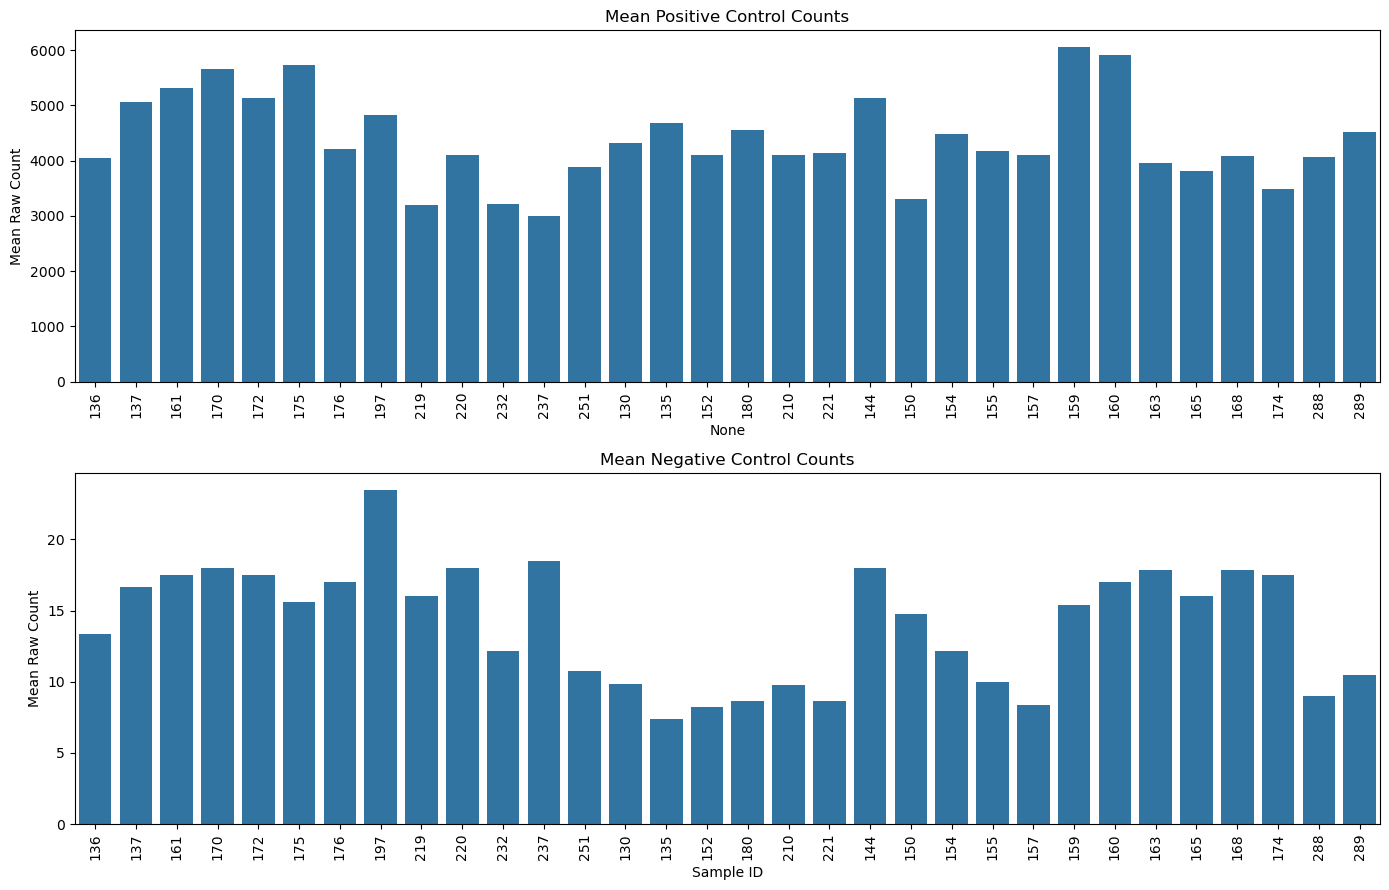

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

sns.barplot(
    x=control_summary.index,
    y=control_summary["Positive_Mean"],
    ax=axes[0]
)

axes[0].set_title("Mean Positive Control Counts")
axes[0].set_ylabel("Mean Raw Count")
axes[0].tick_params(axis="x", rotation=90)

sns.barplot(
    x=control_summary.index,
    y=control_summary["Negative_Mean"],
    ax=axes[1]
)

axes[1].set_title("Mean Negative Control Counts")
axes[1].set_xlabel("Sample ID")
axes[1].set_ylabel("Mean Raw Count")
axes[1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

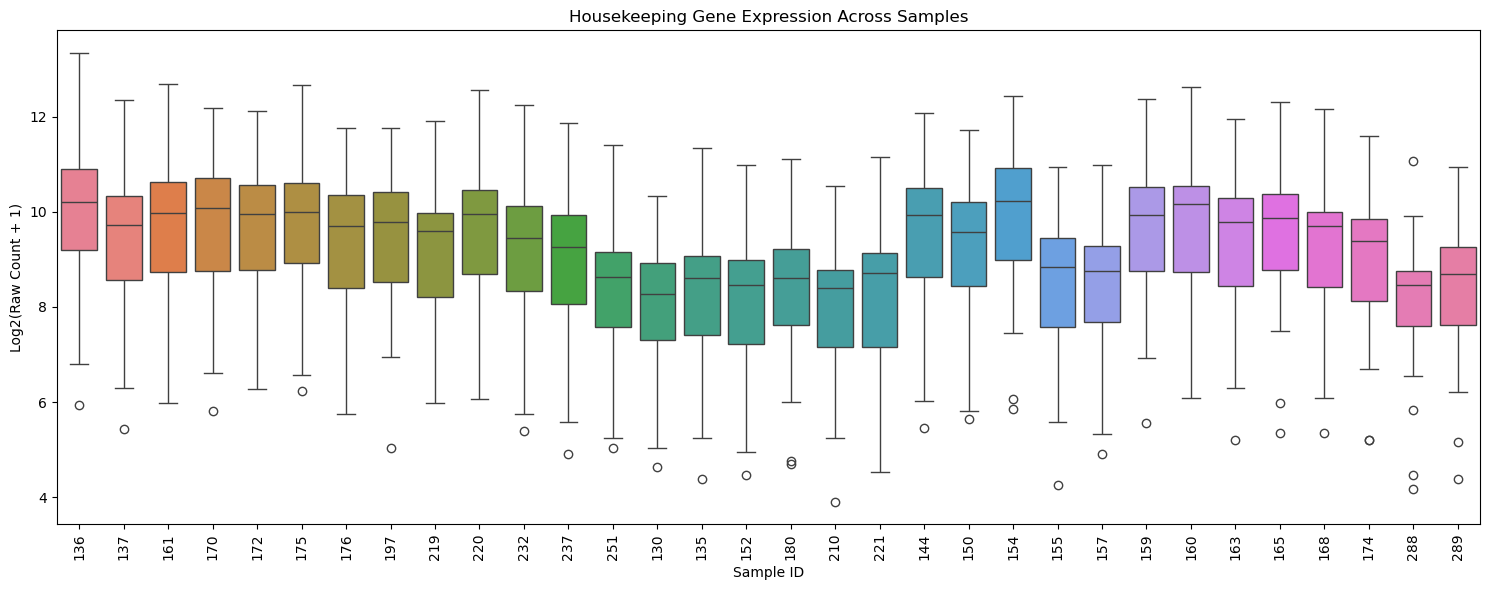

In [16]:
# Extract housekeeping genes
housekeeping = df[
    df["Class Name"] == "Housekeeping"
].set_index("Probe Name")[selected_samples]

housekeeping = housekeeping.apply(
    pd.to_numeric, errors="coerce"
)

housekeeping.columns = sample_ids

# Log transform for visualization
log_housekeeping = np.log2(housekeeping + 1)

plt.figure(figsize=(15, 6))

sns.boxplot(data=log_housekeeping)

plt.title("Housekeeping Gene Expression Across Samples")
plt.xlabel("Sample ID")
plt.ylabel("Log2(Raw Count + 1)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

In [17]:
# Positive-control signal
positive_sum = positive_controls.sum(axis=0)

# Negative-control background
negative_mean = negative_controls.mean(axis=0)
negative_sd = negative_controls.std(axis=0)

# Background threshold: mean + 2 SD
background_threshold = negative_mean + 2 * negative_sd

# Percentage of endogenous genes above background
detected_genes = expression.gt(
    background_threshold, axis=1
).sum(axis=0)

detection_percentage = (
    detected_genes / expression.shape[0]
) * 100

# Summarize QC metrics
qc_metrics = pd.DataFrame({
    "Positive_Control_Sum": positive_sum,
    "Negative_Control_Mean": negative_mean,
    "Background_Threshold": background_threshold,
    "Detected_Genes": detected_genes,
    "Detection_Percentage": detection_percentage
})

display(qc_metrics.round(2))


,Positive_Control_Sum,Negative_Control_Mean,Background_Threshold,Detected_Genes,Detection_Percentage
136,24311,13.38,24.79,590,80.82
137,30383,16.62,29.85,594,81.37
161,31930,17.50,26.18,565,77.40
170,33994,18.00,24.93,568,77.81
172,30852,17.50,26.38,560,76.71
175,34422,15.62,24.31,574,78.63
176,25290,17.00,30.98,574,78.63
197,28963,23.50,65.07,482,66.03
219,19196,16.00,41.90,511,70.00
220,24621,18.00,41.37,528,72.33


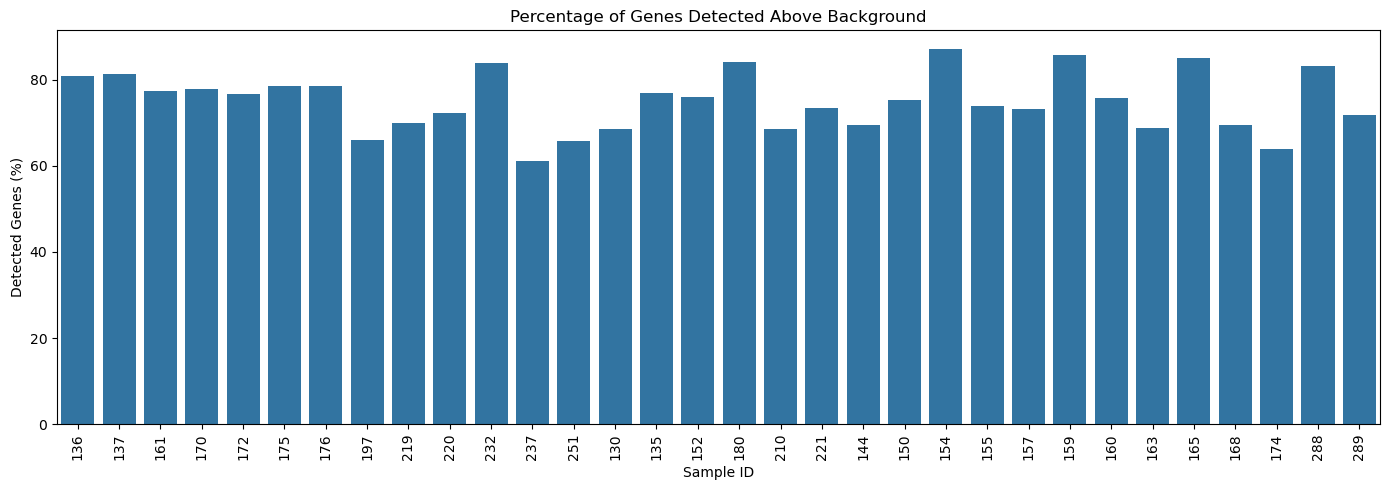

In [18]:
plt.figure(figsize=(14, 5))

sns.barplot(
    x=qc_metrics.index,
    y=qc_metrics["Detection_Percentage"]
)

plt.title("Percentage of Genes Detected Above Background")
plt.xlabel("Sample ID")
plt.ylabel("Detected Genes (%)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

Normalization

In [19]:
# Calculate positive-control normalization factors
positive_sum = positive_controls.sum(axis=0)

reference_sum = positive_sum.mean()

positive_factors = reference_sum / positive_sum

# Create summary table
normalization_qc = pd.DataFrame({
    "Sample_ID": expression.columns,
    "Group": metadata.set_index("Sample_ID").loc[
        expression.columns, "Group"
    ].values,
    "Positive_Control_Sum": positive_sum.values,
    "Positive_Factor": positive_factors.values
})

# Flag potentially extreme factors
normalization_qc["Positive_Factor_Flag"] = (
    (normalization_qc["Positive_Factor"] < 0.3) |
    (normalization_qc["Positive_Factor"] > 3)
)

display(normalization_qc.round(3))

print("\nPositive-control factor summary:")
print(positive_factors.describe())

,Sample_ID,Group,Positive_Control_Sum,Positive_Factor,Positive_Factor_Flag
0,136,Early-onset PE,24311,1.083,False
1,137,Early-onset PE,30383,0.866,False
2,161,Early-onset PE,31930,0.824,False
3,170,Early-onset PE,33994,0.774,False
4,172,Early-onset PE,30852,0.853,False
5,175,Early-onset PE,34422,0.765,False
6,176,Early-onset PE,25290,1.041,False
7,197,Early-onset PE,28963,0.909,False
8,219,Early-onset PE,19196,1.371,False
9,220,Early-onset PE,24621,1.069,False



Positive-control factor summary:
count    32.000000
mean      1.032074
std       0.186783
min       0.724382
25%       0.898068
50%       1.056415
75%       1.089379
max       1.461232
dtype: float64


In [20]:
# Apply positive-control factors for diagnostic purposes
housekeeping_adjusted = housekeeping.mul(
    positive_factors, axis=1
)

# Calculate variation across samples
hk_mean = housekeeping_adjusted.mean(axis=1)
hk_std = housekeeping_adjusted.std(axis=1)

hk_cv = hk_std / hk_mean

housekeeping_stability = pd.DataFrame({
    "Mean_Count": hk_mean,
    "CV": hk_cv
}).sort_values("CV")

print("Housekeeping genes with lowest variation:")
display(housekeeping_stability.head(10).round(3))

print("\nHousekeeping genes with highest variation:")
display(housekeeping_stability.tail(10).round(3))

Housekeeping genes with lowest variation:


,Mean_Count,CV
Probe Name,,
GPATCH3,153.046,0.244
G6PD,306.088,0.338
TLK2,696.473,0.369
MRPS5,1082.342,0.372
EDC3,846.608,0.376
AMMECR1L,707.226,0.382
MTMR14,951.731,0.384
AGK,301.272,0.386
FCF1,1800.604,0.388



Housekeeping genes with highest variation:


,Mean_Count,CV
Probe Name,,
GUSB,1358.996,0.429
CC2D1B,41.754,0.434
ABCF1,1721.837,0.449
USP39,603.097,0.456
ZNF143,771.783,0.461
PPIA,397.026,0.466
DNAJC14,348.884,0.467
NOL7,1374.100,0.469
NUBP1,286.148,0.486


In [21]:
# Select the 10 housekeeping genes with lowest CV
top_hk_genes = housekeeping_stability.head(10).index

# Use positive-control-adjusted values for diagnostics
hk_log = np.log2(
    housekeeping_adjusted.loc[top_hk_genes] + 1
)

# Match sample groups
group_map = metadata.set_index("Sample_ID")["Group"]

# Calculate median expression within each group
hk_group_medians = pd.DataFrame({
    group: hk_log[
        [s for s in hk_log.columns if group_map.loc[s] == group]
    ].median(axis=1)
    for group in ["Early-onset PE", "Late-onset PE", "Healthy"]
})

# Calculate the largest difference in median expression
hk_group_medians["Max_Group_Difference"] = (
    hk_group_medians.max(axis=1) -
    hk_group_medians.min(axis=1)
)

display(hk_group_medians.round(3))

,Early-onset PE,Late-onset PE,Healthy,Max_Group_Difference
Probe Name,,,,
GPATCH3,7.370,6.753,7.479,0.726
G6PD,8.336,7.356,8.375,1.019
TLK2,9.647,8.539,9.676,1.138
MRPS5,10.356,9.167,10.208,1.189
EDC3,9.960,8.807,9.835,1.154
AMMECR1L,9.561,8.451,9.608,1.157
MTMR14,10.047,8.877,9.973,1.170
AGK,8.463,7.432,8.300,1.031
FCF1,10.925,9.826,11.028,1.202


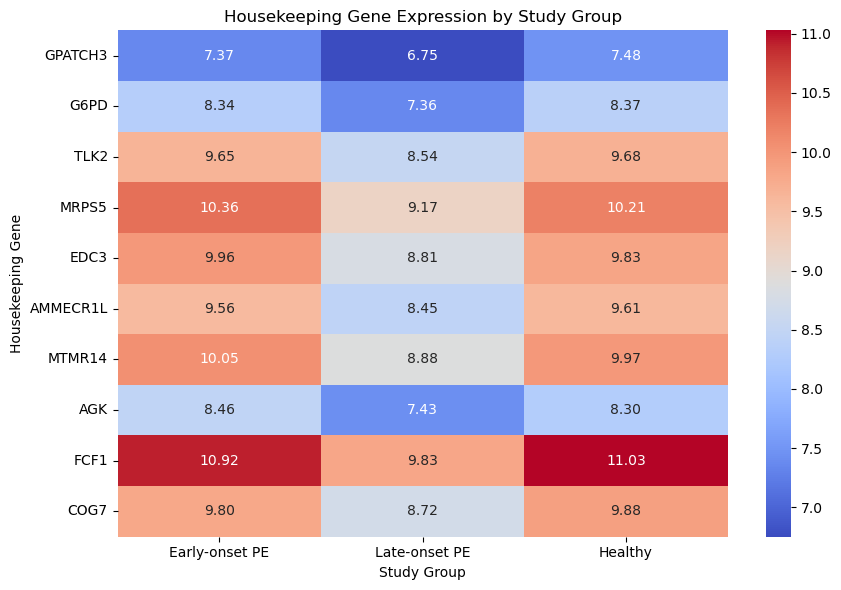

In [22]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    hk_group_medians.drop(columns="Max_Group_Difference"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Housekeeping Gene Expression by Study Group")
plt.xlabel("Study Group")
plt.ylabel("Housekeeping Gene")

plt.tight_layout()
plt.show()

In [23]:
# Calculate log2 housekeeping expression
hk_all_log = np.log2(housekeeping_adjusted + 1)

# Calculate group medians for all housekeeping genes
all_hk_group_medians = pd.DataFrame({
    group: hk_all_log[
        metadata.loc[
            metadata["Group"] == group, "Sample_ID"
        ].tolist()
    ].median(axis=1)
    for group in ["Early-onset PE", "Late-onset PE", "Healthy"]
})

# Compare early-onset and late-onset
all_hk_group_medians["Early_vs_Late"] = (
    all_hk_group_medians["Early-onset PE"] -
    all_hk_group_medians["Late-onset PE"]
)

print("Number of housekeeping genes:",
      len(all_hk_group_medians))

print("\nGenes higher in early-onset:")
print((all_hk_group_medians["Early_vs_Late"] > 0).sum())

print("\nGenes higher in late-onset:")
print((all_hk_group_medians["Early_vs_Late"] < 0).sum())

print("\nSummary of group differences:")
print(all_hk_group_medians["Early_vs_Late"].describe())

Number of housekeeping genes: 40

Genes higher in early-onset:
40

Genes higher in late-onset:
0

Summary of group differences:
count    40.000000
mean      1.266009
std       0.207068
min       0.616843
25%       1.145947
50%       1.272506
75%       1.372598
max       1.885461
Name: Early_vs_Late, dtype: float64


In [24]:
from scipy.stats import gmean

# Geometric mean for each sample
hk_geomean = pd.Series(
    gmean(housekeeping_adjusted, axis=0),
    index=housekeeping_adjusted.columns
)

# Diagnostic normalization factors
hk_factors = hk_geomean.mean() / hk_geomean

hk_factor_summary = pd.DataFrame({
    "Sample_ID": hk_factors.index,
    "HK_Factor": hk_factors.values
})

hk_factor_summary["Group"] = (
    hk_factor_summary["Sample_ID"]
    .map(metadata.set_index("Sample_ID")["Group"])
)

print("Housekeeping factor summary by group:")

display(
    hk_factor_summary.groupby("Group")["HK_Factor"]
    .describe()
    .round(3)
)

Housekeeping factor summary by group:


,count,mean,std,min,25%,50%,75%,max
Group,,,,,,,,
Early-onset PE,13.0,0.882,0.258,0.551,0.732,0.861,0.906,1.648
Healthy,13.0,1.114,0.465,0.636,0.770,0.915,1.574,1.981
Late-onset PE,6.0,2.027,0.200,1.782,1.902,1.982,2.185,2.290


In [25]:
from scipy.stats import gmean
import pandas as pd
import numpy as np

# Ensure positive-control counts are suitable for geometric means
assert positive_controls.notna().all().all()
assert (positive_controls > 0).all().all()

# NanoString positive-control geometric means
pos_geomeans = pd.Series(
    gmean(positive_controls, axis=0),
    index=positive_controls.columns
)

# Calculate scaling factors
pos_factors_geo = pos_geomeans.mean() / pos_geomeans

# Apply to housekeeping genes for diagnostic purposes
hk_pos_adjusted = housekeeping.mul(
    pos_factors_geo, axis=1
)

# Geometric mean of all 40 housekeeping genes
assert (hk_pos_adjusted > 0).all().all()

hk_geomeans = pd.Series(
    gmean(hk_pos_adjusted, axis=0),
    index=hk_pos_adjusted.columns
)

hk_factors_geo = hk_geomeans.mean() / hk_geomeans

# Summarize by study group
factor_check = pd.DataFrame({
    "Sample_ID": expression.columns,
    "Group": metadata.set_index("Sample_ID").loc[
        expression.columns, "Group"
    ].values,
    "Positive_Factor": pos_factors_geo.reindex(
        expression.columns
    ).values,
    "Housekeeping_Factor": hk_factors_geo.reindex(
        expression.columns
    ).values
})

display(
    factor_check.groupby("Group")[
        ["Positive_Factor", "Housekeeping_Factor"]
    ].agg(["mean", "min", "max"]).round(3)
)

Positive_Factor               Housekeeping_Factor              
                          mean    min    max                mean    min    max
Group                                                                         
Early-onset PE           1.029  0.748  1.412               0.880  0.559  1.588
Healthy                  1.023  0.731  1.296               1.099  0.643  1.873
Late-onset PE            1.059  0.984  1.122               1.937  1.671  2.278

In [28]:
from pathlib import Path
from urllib.request import urlretrieve
import gzip
import GEOparse

# Use your existing data directory
soft_path = data_dir / "GSE190639_family.soft.gz"

# HTTPS instead of FTP
url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE190nnn/GSE190639/soft/"
    "GSE190639_family.soft.gz"
)

# Download the file again
urlretrieve(url, soft_path)

# Verify that the compressed file is valid
with gzip.open(soft_path, "rb") as f:
    while f.read(1024 * 1024):
        pass

print("Download complete and gzip file verified!")

# Load the downloaded file directly
gse = GEOparse.get_GEO(
    filepath=str(soft_path),
    silent=True
)

print("Number of GEO samples:", len(gse.gsms))

Download complete and gzip file verified!
Number of GEO samples: 32


GEOparse supports loading an existing SOFT file directly through its filepath argument. It is going to avoid triggering FTP downloaddder agin

In [29]:
# Select first GEO sample
first_gsm = next(iter(gse.gsms.values()))

# Display sample information
print("GEO Sample ID:", first_gsm.name)
print("Sample title:", first_gsm.metadata.get("title"))

# View expression data
print("Columns:", first_gsm.table.columns.tolist())

display(first_gsm.table.head())

GEO Sample ID: GSM5726936
Sample title: ['placenta_eoPE_136']
Columns: ['ID_REF', 'VALUE']


,ID_REF,VALUE
0,A2M-mRNA,12617.670910
1,ABCB1-mRNA,2777.100078
2,ABL1-mRNA,673.188459
3,ADA-mRNA,75.911619
4,ADORA2A-mRNA,27.939693


In [30]:
import pandas as pd

normalized_samples = {}
sample_info = []

for gsm_id, gsm in gse.gsms.items():

    # Get sample title
    title = gsm.metadata["title"][0]

    # Extract sample ID
    sample_id = title.split("_")[-1]

    # Determine sample group
    if "_eoPE_" in title:
        group = "Early-onset PE"
    elif "_loPE_" in title:
        group = "Late-onset PE"
    else:
        group = "Healthy"

    # Extract normalized expression
    sample_data = gsm.table.copy()

    sample_data["ID_REF"] = (
        sample_data["ID_REF"]
        .str.replace(r"-mRNA$", "", regex=True)
    )

    normalized_samples[sample_id] = (
        sample_data.set_index("ID_REF")["VALUE"]
    )

    sample_info.append({
        "GSM_ID": gsm_id,
        "Sample_ID": sample_id,
        "Group": group,
        "Title": title
    })

# Combine samples into a matrix
expression_normalized = pd.DataFrame(normalized_samples)

# Create metadata table
metadata_normalized = pd.DataFrame(sample_info)

print("Normalized expression matrix shape:",
      expression_normalized.shape)

print("\nSample groups:")
print(metadata_normalized["Group"].value_counts())

display(expression_normalized.iloc[:5, :5])

Normalized expression matrix shape: (730, 32)

Sample groups:
Group
Early-onset PE    13
Healthy           13
Late-onset PE      6
Name: count, dtype: int64


,136,137,161,170,172
ID_REF,,,,,
A2M,12617.670910,13050.269080,10454.831750,9170.805780,10511.299570
ABCB1,2777.100078,3873.346124,3797.920060,2473.570114,2964.444969
ABL1,673.188459,627.582110,667.509287,550.885208,569.638445
ADA,75.911619,175.066492,85.061981,40.759137,50.604136
ADORA2A,27.939693,30.480327,36.362374,28.021907,25.302068


In [31]:
# Check for missing values
print(
    "Missing values:",
    expression_normalized.isna().sum().sum()
)

# Check for negative values
print(
    "Negative values:",
    (expression_normalized < 0).sum().sum()
)

# Check number of samples
print(
    "Number of samples:",
    expression_normalized.shape[1]
)

# Check for duplicate gene names
print(
    "Duplicate gene names:",
    expression_normalized.index.duplicated().sum()
)

# Check sample groups
display(metadata_normalized.groupby("Group").size())

Missing values: 0
Negative values: 0
Number of samples: 32
Duplicate gene names: 0


Group
Early-onset PE    13
Healthy           13
Late-onset PE      6
dtype: int64

In [32]:
# Save the normalized expression matrix
expression_normalized.to_csv(
    data_dir / "expression_normalized.csv"
)

# Save normalized sample metadata
metadata_normalized.to_csv(
    data_dir / "metadata_normalized.csv",
    index=False
)

print("Normalized expression data saved successfully!")

Normalized expression data saved successfully!
